In [1]:
import numpy as np
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="white", rc={"xtick.major.pad": 1, "ytick.major.pad": 1})

In [2]:
%matplotlib inline
np.random.seed(sum(map(ord, "palettes")))

In [3]:
# Add colormap display methods to matplotlib colormaps.
# These are forthcoming in matplotlib 3.4, but, the matplotlib display
# method includes the colormap name, which is redundant.
def _repr_png_(self):
    """Generate a PNG representation of the Colormap."""
    import io
    from PIL import Image
    import numpy as np
    IMAGE_SIZE = (400, 50)
    X = np.tile(np.linspace(0, 1, IMAGE_SIZE[0]), (IMAGE_SIZE[1], 1))
    pixels = self(X, bytes=True)
    png_bytes = io.BytesIO()
    Image.fromarray(pixels).save(png_bytes, format='png')
    return png_bytes.getvalue()
    
def _repr_html_(self):
    """Generate an HTML representation of the Colormap."""
    import base64
    png_bytes = self._repr_png_()
    png_base64 = base64.b64encode(png_bytes).decode('ascii')
    return ('<img ' +
            'alt="' + self.name + ' color map" ' +
            'title="' + self.name + '"' +
            'src="data:image/png;base64,' + png_base64 + '">')
    
import matplotlib as mpl
mpl.colors.Colormap._repr_png_ = _repr_png_
mpl.colors.Colormap._repr_html_ = _repr_html_

In [4]:
sns.husl_palette(8, s=.7)

[(0.9050206690302031, 0.485333660078793, 0.5536060216272151),
 (0.7746134071777862, 0.5735064999982632, 0.33461170957219066),
 (0.5960157928303208, 0.6360472513664188, 0.332709174532649),
 (0.33807407728540445, 0.6795473933377336, 0.4531666972263207),
 (0.3534153088659702, 0.6633810279867839, 0.6364737558329581),
 (0.36855688121452856, 0.6460104224517847, 0.7735274903942881),
 (0.6343430589262583, 0.5670865384343673, 0.8832295477118143),
 (0.8878791356686372, 0.4548300970941765, 0.8124926618667797)]

In [5]:
c = sns.color_palette("muted")[0]
sns.blend_palette([sns.desaturate(c, 0), c], 8)

[(np.float64(0.5490196078431373),
  np.float64(0.5490196078431373),
  np.float64(0.5490196078431373)),
 (np.float64(0.5113725490196079),
  np.float64(0.5379469434832757),
  np.float64(0.5866666666666667)),
 (np.float64(0.47267973856209156),
  np.float64(0.526566705113418),
  np.float64(0.625359477124183)),
 (np.float64(0.43503267973856213),
  np.float64(0.5154940407535563),
  np.float64(0.6630065359477124)),
 (np.float64(0.3963398692810458),
  np.float64(0.5041138023836986),
  np.float64(0.7016993464052288)),
 (np.float64(0.35869281045751633),
  np.float64(0.493041138023837),
  np.float64(0.7393464052287582)),
 (np.float64(0.32),
  np.float64(0.48166089965397924),
  np.float64(0.7780392156862745)),
 (np.float64(0.2823529411764706),
  np.float64(0.47058823529411764),
  np.float64(0.8156862745098039))]

In [6]:
sns.blend_palette([".1", c, ".95"], 8)

[(np.float64(0.1), np.float64(0.1), np.float64(0.1)),
 (np.float64(0.1514878892733564),
  np.float64(0.20463667820069203),
  np.float64(0.302076124567474)),
 (np.float64(0.20440599769319492),
  np.float64(0.3121799307958477),
  np.float64(0.5097654748173779)),
 (np.float64(0.25589388696655135),
  np.float64(0.41681660899653983),
  np.float64(0.7118415993848519)),
 (np.float64(0.37922722029988465),
  np.float64(0.5401499423298731),
  np.float64(0.8351749327181853)),
 (np.float64(0.5677393310265282),
  np.float64(0.675513264129181),
  np.float64(0.8730988081507113)),
 (np.float64(0.7614878892733563),
  np.float64(0.814636678200692),
  np.float64(0.912076124567474)),
 (np.float64(0.95), np.float64(0.95), np.float64(0.95))]

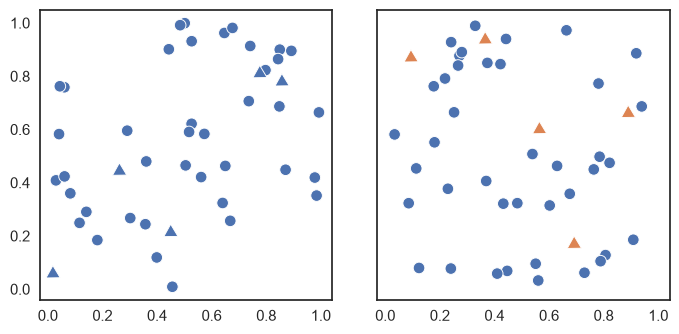

In [7]:
n = 45
rng = np.random.default_rng(200)
x = rng.uniform(0, 1, n * 2)
y = rng.uniform(0, 1, n * 2)
a = np.concatenate([np.zeros(n * 2 - 10), np.ones(10)])

f, axs = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True, sharex=True)

sns.scatterplot(
    x=x[::2], y=y[::2], style=a[::2], size=a[::2], legend=False,
    markers=["o", (3, 1, 1)], sizes=[70, 140], ax=axs[0],
)

sns.scatterplot(
    x=x[1::2], y=y[1::2], style=a[1::2], size=a[1::2], hue=a[1::2], legend=False,
    markers=["o", (3, 1, 1)], sizes=[70, 140], ax=axs[1],
)

f.tight_layout(w_pad=2)

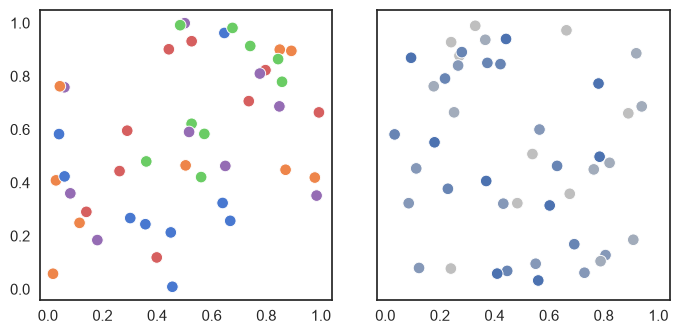

In [8]:
b = np.tile(np.arange(10), n // 5)

f, axs = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True, sharex=True)

sns.scatterplot(
    x=x[::2], y=y[::2], hue=b[::2],
    legend=False, palette="muted", s=70, ax=axs[0],
)

sns.scatterplot(
    x=x[1::2], y=y[1::2], hue=b[1::2],
    legend=False, palette="blend:.75,C0", s=70, ax=axs[1],
)

f.tight_layout(w_pad=2)

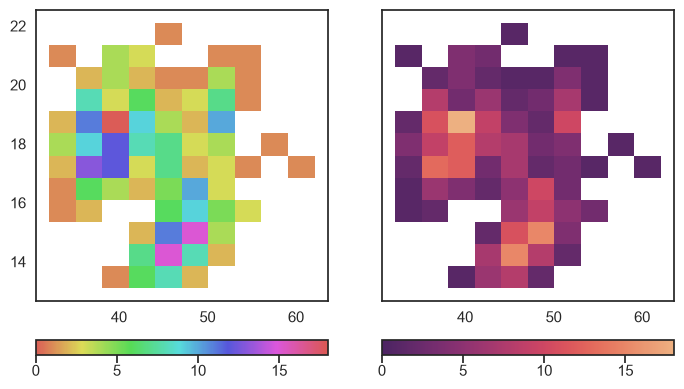

In [9]:
penguins = sns.load_dataset("penguins")

f, axs = plt.subplots(1, 2, figsize=(7, 4.25), sharey=True, sharex=True)

sns.histplot(
    data=penguins, x="bill_length_mm", y="bill_depth_mm",
    binwidth=(3, .75), cmap="hls", ax=axs[0],
    cbar=True, cbar_kws=dict(orientation="horizontal", pad=.1),
)
axs[0].set(xlabel="", ylabel="")


sns.histplot(
    data=penguins, x="bill_length_mm", y="bill_depth_mm",
    binwidth=(3, .75), cmap="flare_r", ax=axs[1],
    cbar=True, cbar_kws=dict(orientation="horizontal", pad=.1),
)
axs[1].set(xlabel="", ylabel="")

f.tight_layout(w_pad=3)

In [10]:
sns.color_palette()

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [11]:
sns.color_palette("tab10")

[(0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 (1.0, 0.4980392156862745, 0.054901960784313725),
 (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 (0.5490196078431373, 0.33725490196078434, 0.29411764705882354),
 (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 (0.4980392156862745, 0.4980392156862745, 0.4980392156862745),
 (0.7372549019607844, 0.7411764705882353, 0.13333333333333333),
 (0.09019607843137255, 0.7450980392156863, 0.8117647058823529)]

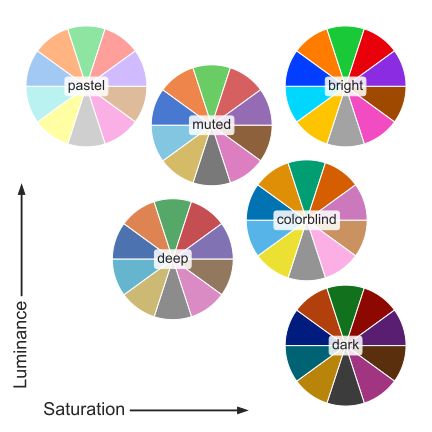

In [12]:
import io
from IPython.display import SVG
f = mpl.figure.Figure(figsize=(6, 6))

ax_locs = dict(
    deep=(.4, .4),
    bright=(.8, .8),
    muted=(.49, .71),
    dark=(.8, .2),
    pastel=(.2, .8),
    colorblind=(.71, .49),
)

s = .35

for pal, (x, y) in ax_locs.items():
    ax = f.add_axes([x - s / 2, y - s / 2, s, s])
    ax.pie(np.ones(10),
           colors=sns.color_palette(pal, 10),
           counterclock=False, startangle=180,
           wedgeprops=dict(linewidth=1, edgecolor="w"))
    f.text(x, y, pal, ha="center", va="center", size=14,
           bbox=dict(facecolor="white", alpha=0.85, boxstyle="round,pad=0.2"))

f.text(.1, .05, "Saturation", size=18, ha="left", va="center",
       bbox=dict(facecolor="white", edgecolor="w"))
f.text(.05, .1, "Luminance", size=18, ha="center", va="bottom", rotation=90,
       bbox=dict(facecolor="white", edgecolor="w"))

ax = f.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.arrow(.15, .05, .4, 0, width=.002, head_width=.015, color=".15")
ax.arrow(.05, .15, 0, .4, width=.002, head_width=.015, color=".15")
ax.set(xlim=(0, 1), ylim=(0, 1))
f.savefig(svg:=io.StringIO(), format="svg")
SVG(svg.getvalue())

In [13]:
sns.color_palette("hls", 8)

[(0.86, 0.3712, 0.33999999999999997),
 (0.86, 0.7612000000000001, 0.33999999999999997),
 (0.5688000000000001, 0.86, 0.33999999999999997),
 (0.33999999999999997, 0.86, 0.5012000000000001),
 (0.33999999999999997, 0.8287999999999999, 0.86),
 (0.33999999999999997, 0.43879999999999986, 0.86),
 (0.6311999999999998, 0.33999999999999997, 0.86),
 (0.86, 0.33999999999999997, 0.6987999999999996)]

In [14]:
sns.color_palette("husl", 8)

[(0.9677975592919913, 0.44127456009157356, 0.5358103155058701),
 (0.8087954113106306, 0.5634700050056693, 0.19502642696727285),
 (0.5920891529639701, 0.6418467016378244, 0.1935069134991043),
 (0.19783576093349015, 0.6955516966063037, 0.3995301037444499),
 (0.21044753832183283, 0.6773105080456748, 0.6433941168468681),
 (0.22335772267769388, 0.6565792317435265, 0.8171355503265633),
 (0.6423044349219739, 0.5497680051256467, 0.9582651433656727),
 (0.96038885399407, 0.3814317878772117, 0.8683117650835491)]

In [15]:
sns.color_palette("Set2")

[(0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254)]

In [16]:
sns.color_palette("Paired")

[(0.6509803921568628, 0.807843137254902, 0.8901960784313725),
 (0.12156862745098039, 0.47058823529411764, 0.7058823529411765),
 (0.6980392156862745, 0.8745098039215686, 0.5411764705882353),
 (0.2, 0.6274509803921569, 0.17254901960784313),
 (0.984313725490196, 0.6039215686274509, 0.6),
 (0.8901960784313725, 0.10196078431372549, 0.10980392156862745),
 (0.9921568627450981, 0.7490196078431373, 0.43529411764705883),
 (1.0, 0.4980392156862745, 0.0),
 (0.792156862745098, 0.6980392156862745, 0.8392156862745098),
 (0.41568627450980394, 0.23921568627450981, 0.6039215686274509),
 (1.0, 1.0, 0.6),
 (0.6941176470588235, 0.34901960784313724, 0.1568627450980392)]

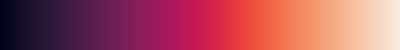

In [17]:
sns.color_palette("rocket", as_cmap=True)

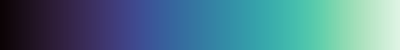

In [18]:
sns.color_palette("mako", as_cmap=True)

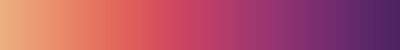

In [19]:
sns.color_palette("flare", as_cmap=True)

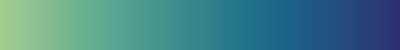

In [20]:
sns.color_palette("crest", as_cmap=True)

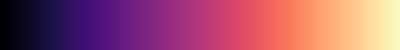

In [21]:
sns.color_palette("magma", as_cmap=True)

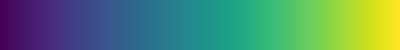

In [22]:
sns.color_palette("viridis", as_cmap=True)

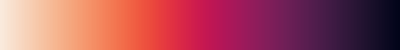

In [23]:
sns.color_palette("rocket_r", as_cmap=True)

In [24]:
sns.color_palette("rocket")

[(0.20973515, 0.09747934, 0.24238489),
 (0.43860848, 0.12177004, 0.34119475),
 (0.67824099, 0.09192342, 0.3504148),
 (0.8833417, 0.19830556, 0.26014181),
 (0.95381595, 0.46373781, 0.31769923),
 (0.96516917, 0.70776351, 0.5606593)]

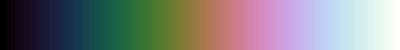

In [25]:
sns.color_palette("cubehelix", as_cmap=True)

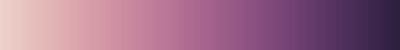

In [26]:
sns.cubehelix_palette(as_cmap=True)

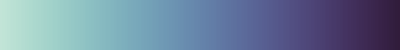

In [27]:
sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)

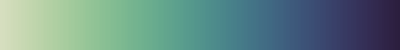

In [28]:
sns.cubehelix_palette(start=.5, rot=-.75, as_cmap=True)

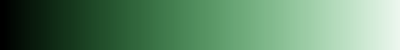

In [29]:
sns.cubehelix_palette(start=2, rot=0, dark=0, light=.95, reverse=True, as_cmap=True)

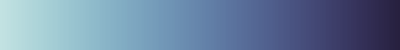

In [30]:
sns.color_palette("ch:start=.2,rot=-.3", as_cmap=True)

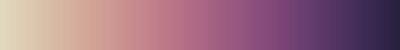

In [31]:
sns.color_palette("ch:s=-.2,r=.6", as_cmap=True)

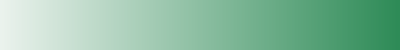

In [32]:
sns.light_palette("seagreen", as_cmap=True)

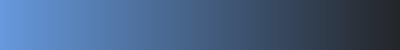

In [33]:
sns.dark_palette("#69d", reverse=True, as_cmap=True)

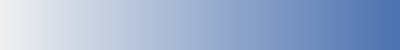

In [34]:
sns.color_palette("light:b", as_cmap=True)

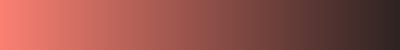

In [35]:
sns.color_palette("dark:salmon_r", as_cmap=True)

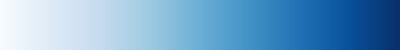

In [36]:
sns.color_palette("Blues", as_cmap=True)

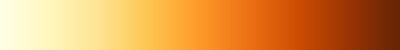

In [37]:
sns.color_palette("YlOrBr", as_cmap=True)

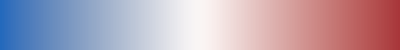

In [38]:
sns.color_palette("vlag", as_cmap=True)

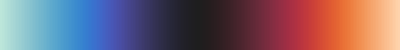

In [39]:
sns.color_palette("icefire", as_cmap=True)

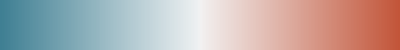

In [40]:
sns.diverging_palette(220, 20, as_cmap=True)

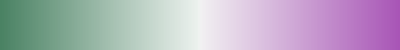

In [41]:
sns.diverging_palette(145, 300, s=60, as_cmap=True)

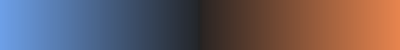

In [42]:
sns.diverging_palette(250, 30, l=65, center="dark", as_cmap=True)

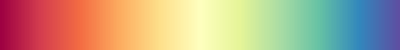

In [43]:
sns.color_palette("Spectral", as_cmap=True)

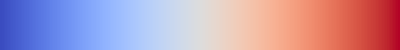

In [44]:
sns.color_palette("coolwarm", as_cmap=True)